In [86]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.stats import genextreme
from scipy.stats import genpareto

In [87]:
ticker = "^GSPC"

data = yf.download(
    ticker,
    start="2011-11-01",
    end="2021-12-29",
    auto_adjust=False,
    progress=False
)

prices = data["Close"].squeeze()

print("Number of prices:", len(prices))
print("First date:", prices.index[0])
print("Last date:", prices.index[-1])

log_returns = np.log(prices / prices.shift(1)).dropna()

print("Number of log returns:", len(log_returns))
print("First return date:", log_returns.index[0])
print("Last return date:", log_returns.index[-1])

Number of prices: 2556
First date: 2011-11-01 00:00:00
Last date: 2021-12-28 00:00:00
Number of log returns: 2555
First return date: 2011-11-02 00:00:00
Last return date: 2021-12-28 00:00:00


In [88]:
V = 1_000_000
losses = -V * log_returns.to_numpy()


def empirical_var(alpha):
    index = int(np.ceil(N * alpha)) - 1
    return sorted_losses[index]

alphas = 0.99 + np.arange(101) * 0.000099
print(alphas[0])
print(alphas[-1])
print(len(alphas))

0.99
0.9999
101


# (1)

In [89]:
sorted_losses = np.sort(losses)
N = len(sorted_losses)

var_empirical = np.array([
    empirical_var(a)
    for a in alphas
])

var_empirical_9999 = empirical_var(0.9999)

print("Empirical VaR at alpha=0.9999:",
      var_empirical_9999)

Empirical VaR at alpha=0.9999: 127652.19747281742


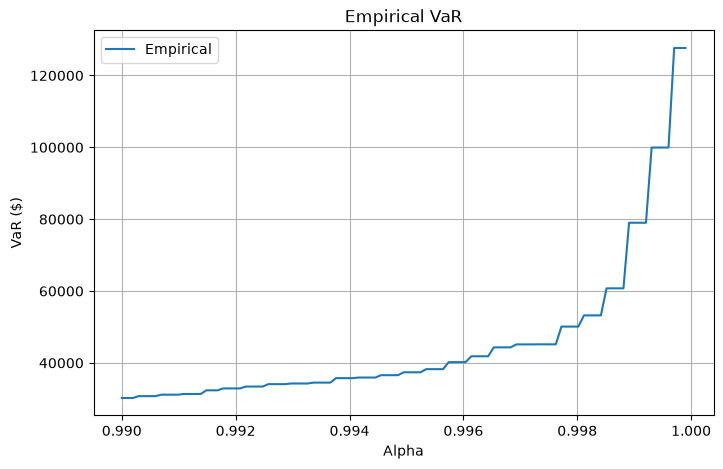

In [90]:
plt.figure(figsize=(8, 5))

plt.plot(
    alphas,
    var_empirical,
    label="Empirical"
)

plt.xlabel("Alpha")
plt.ylabel("VaR ($)")
plt.title("Empirical VaR")
plt.legend()
plt.grid(True)

plt.show()

# （2）

In [91]:
lambda_ewma = 0.97
theta_ewma = 0.97
init_window = 100

ewma_returns = log_returns.loc[:"2021-11-01"].to_numpy()

print("Number of returns used for EWMA:", len(ewma_returns))
print("Last return date used:",
      log_returns.loc[:"2021-11-01"].index[-1])

initial_returns = ewma_returns[:init_window]

mu_hat = np.mean(initial_returns)
sigma2_hat = np.var(initial_returns, ddof=1)

for x in ewma_returns[init_window:]:
    diff = x - mu_hat

    sigma2_hat = (
        theta_ewma * sigma2_hat
        + (1 - theta_ewma) * diff**2
    )

    mu_hat = (
        lambda_ewma * mu_hat
        + (1 - lambda_ewma) * x
    )

sigma_hat = np.sqrt(sigma2_hat)

print("EWMA mean:", mu_hat)
print("EWMA variance:", sigma2_hat)
print("EWMA std:", sigma_hat)

Number of returns used for EWMA: 2516
Last return date used: 2021-11-01 00:00:00
EWMA mean: 0.001210095524848293
EWMA variance: 5.223054728437962e-05
EWMA std: 0.0072270704496621326


In [92]:
z_alpha = norm.ppf(alphas)

var_normal = (
    -V * mu_hat
    + V * sigma_hat * z_alpha
)

var_normal_9999 = (
    -V * mu_hat
    + V * sigma_hat * norm.ppf(0.9999)
)

print("Normal-EWMA VaR at alpha=0.9999:",
      var_normal_9999)

Normal-EWMA VaR at alpha=0.9999: 25667.49861899498


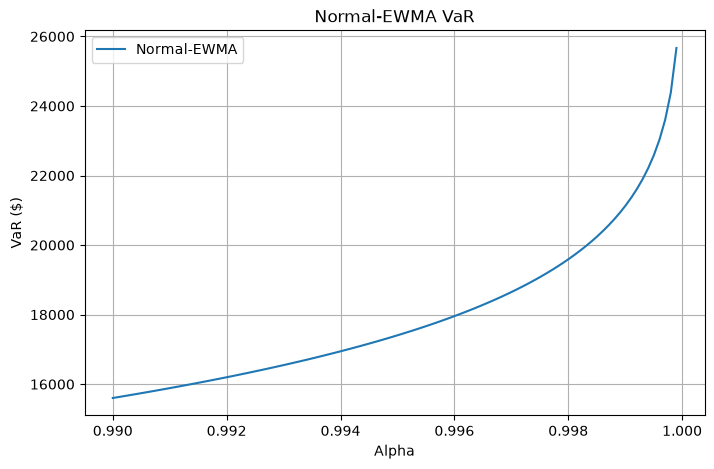

In [93]:
plt.figure(figsize=(8, 5))

plt.plot(
    alphas,
    var_normal,
    label="Normal-EWMA"
)

plt.xlabel("Alpha")
plt.ylabel("VaR ($)")
plt.title("Normal-EWMA VaR")
plt.legend()
plt.grid(True)

plt.show()

# （3）

In [94]:
def gev_block_method(losses, n, alphas):
    N = len(losses)
    m = N // n

    assert m * n == N

    blocks = losses.reshape(m, n)
    block_maxima = np.max(blocks, axis=1)

    # Standardize block maxima for numerical stability
    center = np.mean(block_maxima)
    spread = np.std(block_maxima)

    z = (block_maxima - center) / spread

    # Fit GEV to standardized maxima
    c, loc_z, scale_z = genextreme.fit(z)

    # Convert parameters back to dollar scale
    loc = center + spread * loc_z
    scale = spread * scale_z

    xi = -c

    # Daily VaR -> block maximum probability
    block_probs = alphas**n

    # Quantiles on standardized scale
    q_z = genextreme.ppf(
        block_probs,
        c,
        loc=loc_z,
        scale=scale_z
    )

    # Convert VaR back to dollars
    var_gev = center + spread * q_z

    return {
        "n": n,
        "m": m,
        "block_maxima": block_maxima,
        "c": c,
        "xi": xi,
        "mu": loc,
        "sigma": scale,
        "var": var_gev
    }

In [95]:
gev_73 = gev_block_method(
    losses,
    n=73,
    alphas=alphas
)

print("Block size n =", gev_73["n"])
print("Number of blocks m =", gev_73["m"])

print("SciPy c =", gev_73["c"])
print("GEV xi =", gev_73["xi"])
print("GEV mu =", gev_73["mu"])
print("GEV sigma =", gev_73["sigma"])

print(
    "GEV VaR at alpha=0.9999:",
    gev_73["var"][-1]
)

Block size n = 73
Number of blocks m = 35
SciPy c = -0.17927560250245417
GEV xi = 0.17927560250245417
GEV mu = 28351.4529012299
GEV sigma = 13509.143201765577
GEV VaR at alpha=0.9999: 135033.1986883835


In [96]:
gev_35 = gev_block_method(
    losses,
    n=35,
    alphas=alphas
)

print("Block size n =", gev_35["n"])
print("Number of blocks m =", gev_35["m"])

print("SciPy c =", gev_35["c"])
print("GEV xi =", gev_35["xi"])
print("GEV mu =", gev_35["mu"])
print("GEV sigma =", gev_35["sigma"])

print(
    "GEV VaR at alpha=0.9999:",
    gev_35["var"][-1]
)

Block size n = 35
Number of blocks m = 73
SciPy c = -0.15694806529042876
GEV xi = 0.15694806529042876
GEV mu = 22438.771814530734
GEV sigma = 12853.878606407377
GEV VaR at alpha=0.9999: 139482.80776826257


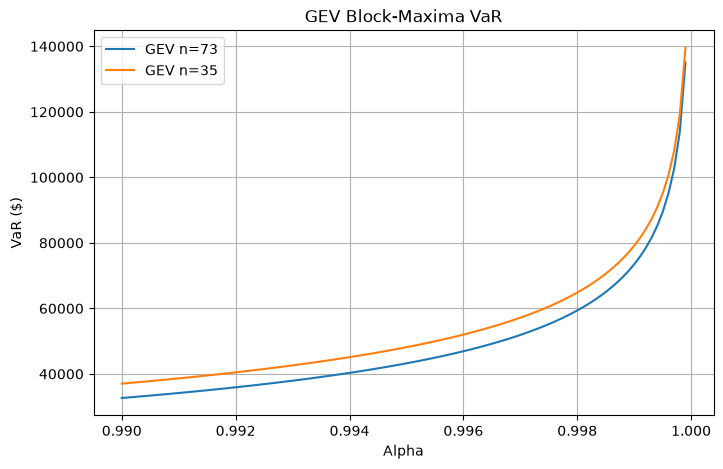

In [97]:
plt.figure(figsize=(8, 5))

plt.plot(
    alphas,
    gev_73["var"],
    label="GEV n=73"
)

plt.plot(
    alphas,
    gev_35["var"],
    label="GEV n=35"
)

plt.xlabel("Alpha")
plt.ylabel("VaR ($)")
plt.title("GEV Block-Maxima VaR")
plt.legend()
plt.grid(True)

plt.show()

# （4）

In [98]:
u = empirical_var(0.95)

excesses = losses[losses > u] - u

print("Threshold u:", u)
print("Number of exceedances:", len(excesses))
print("Exceedance proportion:", len(excesses) / len(losses))

excess_scale = np.std(excesses)
z_excesses = excesses / excess_scale
xi_hat, loc_z, beta_z = genpareto.fit(
    z_excesses,
    floc=0
)
beta_hat = beta_z * excess_scale
print("GPD xi:", xi_hat)
print("GPD beta:", beta_hat)

Threshold u: 15252.860825944299
Number of exceedances: 127
Exceedance proportion: 0.04970645792563601
GPD xi: 0.26558284987877173
GPD beta: 7594.037060022737


In [99]:
F_u = 0.95

if abs(xi_hat) > 1e-8:
    var_gpd = (
        u
        + beta_hat / xi_hat
        * (
            ((1 - F_u) / (1 - alphas))**xi_hat
            - 1
        )
    )
else:
    var_gpd = (
        u
        + beta_hat
        * np.log(
            (1 - F_u) / (1 - alphas)
        )
    )

var_gpd_9999 = var_gpd[-1]

print("GPD VaR at alpha=0.9999:",
      var_gpd_9999)

GPD VaR at alpha=0.9999: 135620.09382225072


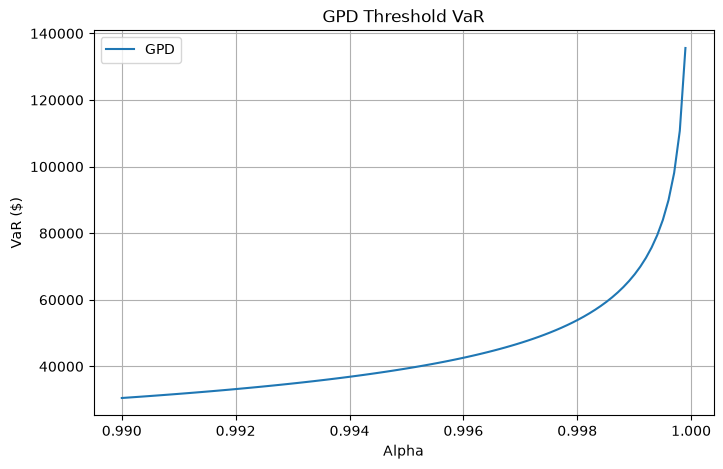

In [100]:
plt.figure(figsize=(8, 5))

plt.plot(
    alphas,
    var_gpd,
    label="GPD"
)

plt.xlabel("Alpha")
plt.ylabel("VaR ($)")
plt.title("GPD Threshold VaR")
plt.legend()
plt.grid(True)

plt.show()

In [101]:
results_9999 = {
    "Empirical": var_empirical_9999,
    "Normal-EWMA": var_normal_9999,
    "GEV n=73": gev_73["var"][-1],
    "GEV n=35": gev_35["var"][-1],
    "GPD": var_gpd_9999
}

for method, value in results_9999.items():
    print(f"{method}: ${value:,.2f}")

Empirical: $127,652.20
Normal-EWMA: $25,667.50
GEV n=73: $135,033.20
GEV n=35: $139,482.81
GPD: $135,620.09


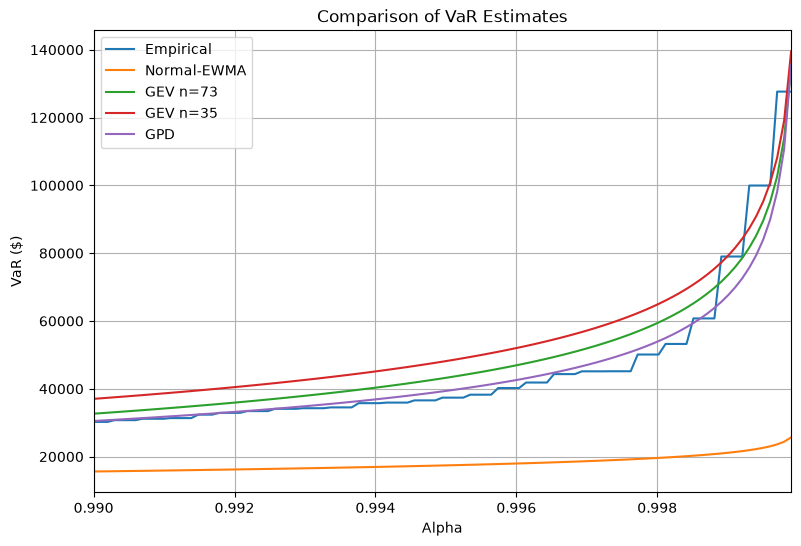

In [102]:
plt.figure(figsize=(9, 6))

plt.plot(alphas, var_empirical, label="Empirical")
plt.plot(alphas, var_normal, label="Normal-EWMA")
plt.plot(alphas, gev_73["var"], label="GEV n=73")
plt.plot(alphas, gev_35["var"], label="GEV n=35")
plt.plot(alphas, var_gpd, label="GPD")

plt.xlabel("Alpha")
plt.ylabel("VaR ($)")
plt.title("Comparison of VaR Estimates")
plt.legend()
plt.grid(True)

plt.xlim(0.99, 0.9999)

plt.show()